# Part 1.3: Trends in rent, income, burden, and prices

How have rents, incomes, and the severe rent burden moved since 2010, how unevenly across states, and what happened
around 2020 and 2021? Four questions:

1. Did rent outgrow income?
2. How has the target (severe rent burden) moved, and how much do states differ?
3. What happened to growth rates and the labor market around COVID?
4. Do states keep their place in the ranking over time?

Everything uses the panel. ACS has no 2020 release, so ACS lines break at 2020 instead of bridging it.

In [1]:
import sys
sys.path.insert(0, "src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from viz import apply_style, SERIES, save_figure, end_label, dot, SURFACE, INK_2, MUTED, DEEMPHASIS, BASELINE

apply_style()
pd.set_option("display.width", 200)
RED = "#e34948"   # diverging pole, paired with the blue slot (not a status color here)

panel = pd.read_csv("data/processed/panel.csv", dtype={"state_fips": str})
acs = panel[panel.acs_available == 1].copy()
names = panel.groupby("state_abbr").state_name.first()
YEARS = list(range(2010, 2025))

def wide(col, df=panel):
    return df.pivot(index="state_abbr", columns="year", values=col).reindex(columns=range(2010, 2026))

## 1. Rent and income, indexed to 2010 = 100

Each line is the median across states of that state's own index, so no single large state dominates. All series share
one axis because they are indexed to a common base. The national CPI for rent of primary residence is the same for
every state. The ACS lines break at 2020.

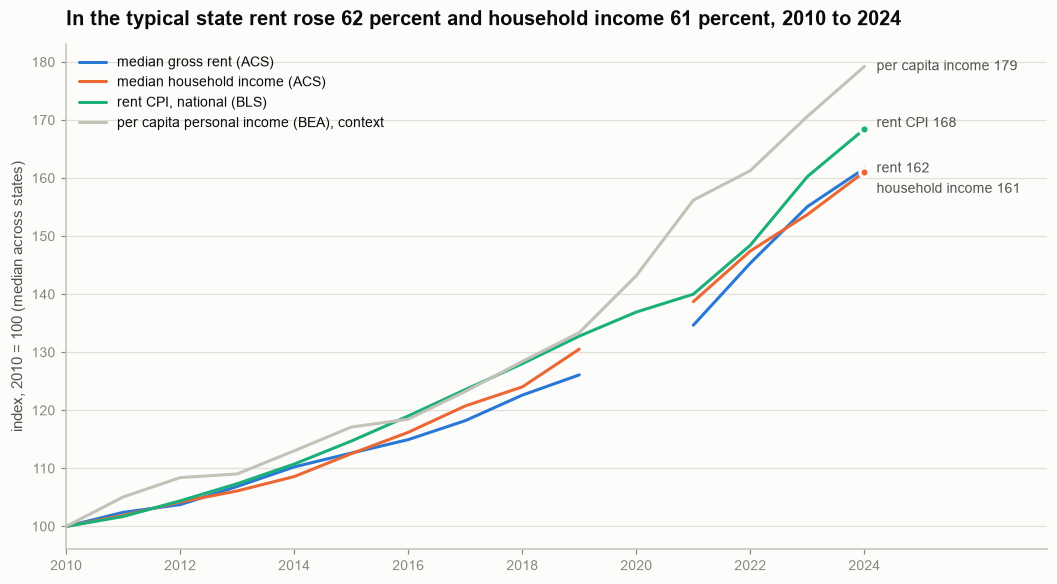

year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
median gross rent (ACS),100.0,102.4,103.8,106.9,110.2,112.6,114.9,118.2,122.6,126.1,NaN,134.7,145.4,155.1,161.6
median household income (ACS),100.0,101.9,104.2,106.1,108.6,112.5,116.2,120.8,124.0,130.5,NaN,138.7,147.4,153.7,161.1
per capita personal income (BEA),100.0,105.1,108.4,109.0,113.0,117.1,118.5,123.2,128.4,133.4,143.2,156.2,161.3,170.6,179.2
"rent CPI, national (BLS)",100.0,101.7,104.4,107.4,110.7,114.7,119.0,123.6,128.0,132.8,136.9,140.0,148.4,160.3,168.4


In [2]:
def median_index(col):
    w = wide(col)
    return (w.div(w[2010], axis=0) * 100).median()

idx = pd.DataFrame({
    "median gross rent (ACS)": median_index("median_gross_rent"),
    "median household income (ACS)": median_index("median_hh_income"),
    "per capita personal income (BEA)": median_index("per_capita_personal_income"),
}).loc[2010:2024]
cpi = panel.groupby("year").cpi_rent_primary_residence.first()
idx["rent CPI, national (BLS)"] = (cpi / cpi[2010] * 100).loc[2010:2024]
end = idx.loc[2024]

fig, ax = plt.subplots(figsize=(9.5, 5.2))
order = ["median gross rent (ACS)", "median household income (ACS)", "rent CPI, national (BLS)"]
for name, color in zip(order, SERIES[:3]):
    ax.plot(idx.index, idx[name], color=color)
    dot(ax, 2024, idx[name].iloc[-1], color)
ax.plot(idx.index, idx["per capita personal income (BEA)"], color=DEEMPHASIS)   # context series in the de-emphasis gray
end_label(ax, 2024, end["median gross rent (ACS)"], f"rent {end['median gross rent (ACS)']:.0f}", dx=8)
end_label(ax, 2024, end["median household income (ACS)"] - 3, f"household income {end['median household income (ACS)']:.0f}", dx=8)
end_label(ax, 2024, end["rent CPI, national (BLS)"] + 1, f"rent CPI {end['rent CPI, national (BLS)']:.0f}", dx=8)
end_label(ax, 2024, end["per capita personal income (BEA)"], f"per capita income {end['per capita personal income (BEA)']:.0f}", dx=8)
ax.set_xlim(2010, 2027.2)
ax.set_xticks([2010, 2012, 2014, 2016, 2018, 2020, 2022, 2024])
ax.set_ylabel("index, 2010 = 100 (median across states)")
ax.grid(axis="x", visible=False)
ax.set_title(f"In the typical state rent rose {end['median gross rent (ACS)'] - 100:.0f} percent and household income {end['median household income (ACS)'] - 100:.0f} percent, 2010 to 2024")
ax.legend(handles=[plt.Line2D([0], [0], color=c) for c in SERIES[:3]] + [plt.Line2D([0], [0], color=DEEMPHASIS)],
          labels=order + ["per capita personal income (BEA), context"], loc="upper left")
save_figure(fig, "03_indexed_rent_income")
plt.show()
display(idx.round(1).T)

The median state hides the spread. Across states, the gap between how much rent and how much income rose from 2010
to 2024, in index points (positive means rent outgrew income):

rent outgrew income in 38 of 51 states; median gap 2.9 points; interquartile range -0.3 to 11.1


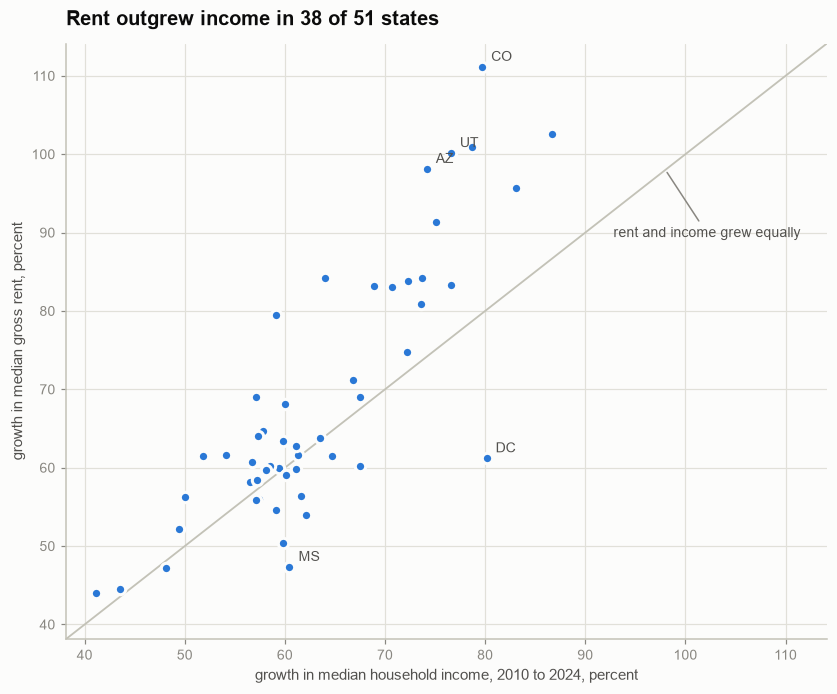

,rent_growth,income_growth,gap,state
state_abbr,,,,
CO,111.1,79.7,31.4,Colorado
AZ,98.1,74.2,23.9,Arizona
UT,100.1,76.6,23.6,Utah
WA,100.9,78.7,22.2,Washington
NV,79.5,59.1,20.4,Nevada
TX,84.1,64.0,20.2,Texas
FL,91.3,75.0,16.3,Florida
ID,102.6,86.6,16.0,Idaho


In [3]:
r, i = wide("median_gross_rent"), wide("median_hh_income")
cum = pd.DataFrame({"rent_growth": 100 * (r[2024] / r[2010] - 1), "income_growth": 100 * (i[2024] / i[2010] - 1)})
cum["gap"] = cum.rent_growth - cum.income_growth
n_up = int((cum.gap > 0).sum())
print(f"rent outgrew income in {n_up} of 51 states; median gap {cum.gap.median():.1f} points; "
      f"interquartile range {cum.gap.quantile(.25):.1f} to {cum.gap.quantile(.75):.1f}")

fig, ax = plt.subplots(figsize=(7.5, 6.2))
lim = [cum[["rent_growth", "income_growth"]].min().min() - 3, cum[["rent_growth", "income_growth"]].max().max() + 3]
ax.plot(lim, lim, color=BASELINE, lw=1.2, zorder=1)
ax.scatter(cum.income_growth, cum.rent_growth, s=46, color=SERIES[0], edgecolor=SURFACE, linewidth=2, zorder=3)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("growth in median household income, 2010 to 2024, percent")
ax.set_ylabel("growth in median gross rent, percent")
ax.set_title(f"Rent outgrew income in {n_up} of 51 states")
ax.annotate("rent and income grew equally", (98, 98), xytext=(-34, -44), textcoords="offset points", fontsize=9, color=INK_2,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=1))
for st in list(cum.gap.nlargest(3).index) + list(cum.gap.nsmallest(2).index):
    ax.annotate(st, (cum.income_growth[st], cum.rent_growth[st]), xytext=(6, 4), textcoords="offset points", fontsize=9, color=INK_2)
save_figure(fig, "03_rent_vs_income_growth")
plt.show()
display(cum.round(1).sort_values("gap", ascending=False).head(8).assign(state=lambda d: d.index.map(names)))

## 2. How the target has moved

Severe rent burden over time. All 51 states in gray, the median in dark gray, and three states highlighted: the highest in
2024 (Florida), Kentucky, and one of the lowest (North Dakota). Color follows the state, not its rank.

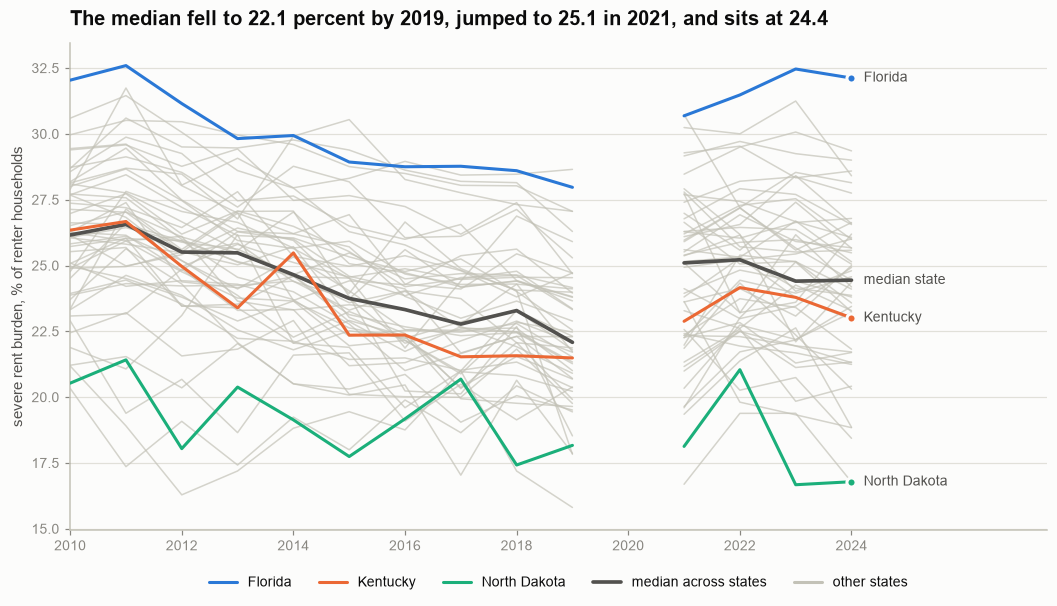

year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
median,26.2,26.6,25.5,25.5,24.7,23.8,23.3,22.8,23.3,22.1,NaN,25.1,25.2,24.4,24.4
25th pct,24.2,24.8,24.3,23.5,23.3,22.4,21.8,21.0,22.0,20.5,NaN,22.3,22.8,22.3,22.4
75th pct,27.8,28.1,27.1,26.9,26.2,25.5,24.8,24.7,24.6,24.1,NaN,26.7,26.7,26.7,26.0
min,20.3,17.4,16.3,17.2,18.8,17.7,18.8,17.0,17.2,15.8,NaN,16.7,19.4,16.7,16.8
max,32.0,32.6,31.2,30.0,29.9,30.5,29.0,28.8,28.6,28.7,NaN,30.7,31.5,32.5,32.1


In [4]:
sv = wide("severe_rent_burden_pct").loc[:, 2010:2024]
med = sv.median()
hi = {"FL": SERIES[0], "KY": SERIES[1], "ND": SERIES[2]}

fig, ax = plt.subplots(figsize=(9.5, 5.4))
for st in sv.index:
    if st not in hi:
        ax.plot(sv.columns, sv.loc[st], color=DEEMPHASIS, lw=1, alpha=0.7, zorder=1)
ax.plot(sv.columns, med, color=INK_2, lw=2.4, zorder=3)
for st, c in hi.items():
    ax.plot(sv.columns, sv.loc[st], color=c, zorder=4)
    dot(ax, 2024, sv.loc[st, 2024], c)
    end_label(ax, 2024, sv.loc[st, 2024], names[st], dx=8)
end_label(ax, 2024, med[2024], "median state", dx=8, color=INK_2)
ax.set_xlim(2010, 2027.5)
ax.set_xticks([2010, 2012, 2014, 2016, 2018, 2020, 2022, 2024])
ax.set_ylabel("severe rent burden, % of renter households")
ax.grid(axis="x", visible=False)
ax.set_title(f"The median fell to {med[2019]:.1f} percent by 2019, jumped to {med[2021]:.1f} in 2021, and sits at {med[2024]:.1f}")
ax.legend(handles=[plt.Line2D([0], [0], color=c) for c in hi.values()] + [plt.Line2D([0], [0], color=INK_2, lw=2.4), plt.Line2D([0], [0], color=DEEMPHASIS)],
          labels=[names[s] for s in hi] + ["median across states", "other states"], loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=5)
save_figure(fig, "03_severe_burden_over_time")
plt.show()
display(pd.DataFrame({"median": med, "25th pct": sv.quantile(.25), "75th pct": sv.quantile(.75), "min": sv.min(), "max": sv.max()}).round(1).T)

The change in rent as a share of income, 2010 to 2024, for every state (annual median rent over annual median
household income). Red bars rose, blue bars fell.

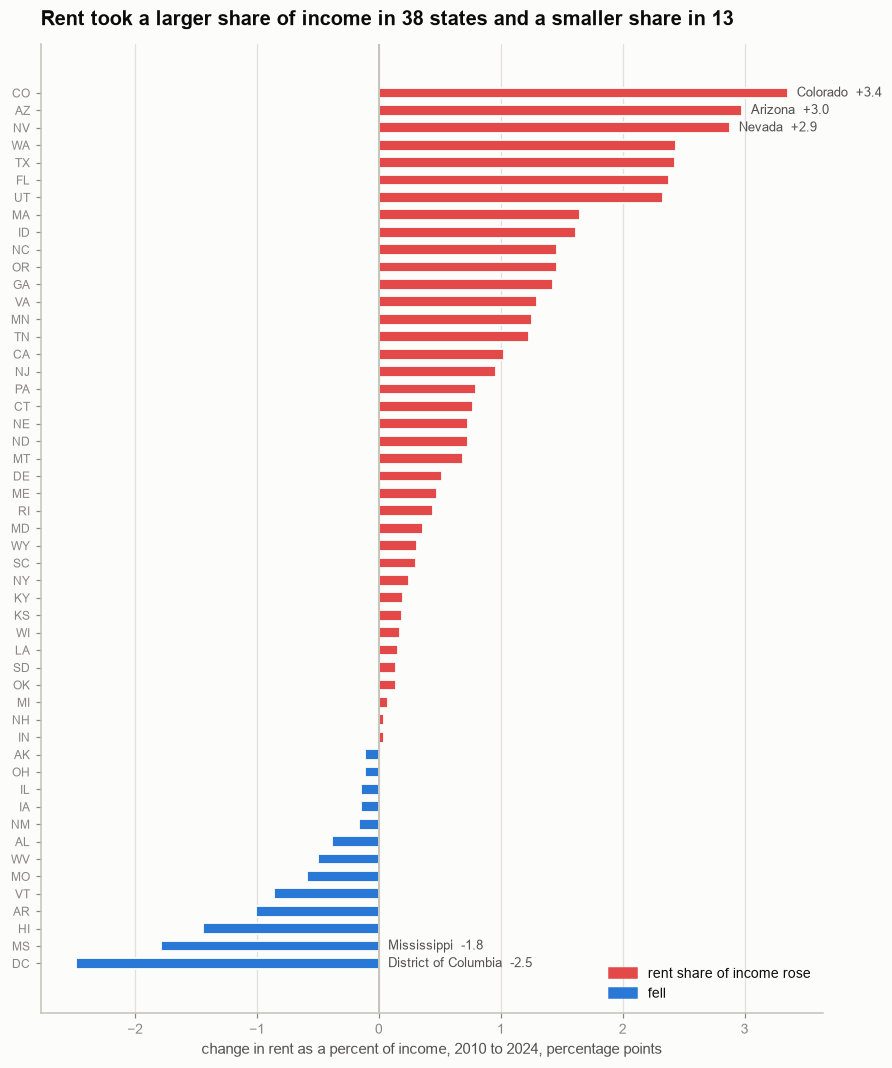

,2010,2024,change,state
state_abbr,,,,
CO,19.16,22.51,3.35,Colorado
AZ,21.65,24.62,2.98,Arizona
NV,22.40,25.28,2.88,Nevada
WA,19.59,22.02,2.44,Washington
TX,19.77,22.20,2.43,Texas
FL,25.59,27.97,2.38,Florida
UT,17.45,19.78,2.33,Utah
MA,19.51,21.15,1.65,Massachusetts
ID,18.85,20.46,1.62,Idaho


In [5]:
rti = wide("rent_to_income_pct")
chg = (rti[2024] - rti[2010]).sort_values()
n_rise, n_fall = int((chg > 0).sum()), int((chg < 0).sum())

fig, ax = plt.subplots(figsize=(8, 9.6))
colors = [RED if v > 0 else SERIES[0] for v in chg.values]
ax.barh(range(len(chg)), chg.values, height=0.62, color=colors, edgecolor=SURFACE, linewidth=1.2, zorder=2)
ax.set_yticks(range(len(chg)), chg.index, fontsize=8)
ax.axvline(0, color=BASELINE, lw=1.2, zorder=3)
ax.grid(axis="y", visible=False)
ax.set_xlabel("change in rent as a percent of income, 2010 to 2024, percentage points")
ax.set_title(f"Rent took a larger share of income in {n_rise} states and a smaller share in {n_fall}")
for st in list(chg.index[-3:]) + list(chg.index[:2]):
    v = chg[st]
    # labels for rising bars sit at the bar end; labels for falling bars sit to the right of zero, clear of the state ticks
    ax.annotate(f"{names[st]}  {v:+.1f}", (max(v, 0), list(chg.index).index(st)), xytext=(6, 0), textcoords="offset points",
                ha="left", va="center", fontsize=8.5, color=INK_2)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=RED), plt.Rectangle((0, 0), 1, 1, color=SERIES[0])],
          labels=["rent share of income rose", "fell"], loc="lower right")
save_figure(fig, "03_rent_to_income_change")
plt.show()
display(pd.DataFrame({"2010": rti[2010], "2024": rti[2024], "change": chg}).round(2).sort_values("change", ascending=False).assign(state=lambda d: d.index.map(names)).head(10))

## 3. Growth and the labor market around COVID

Median across states with the interquartile band. 2021 growth rates do not exist (2020 is missing), so those lines break.

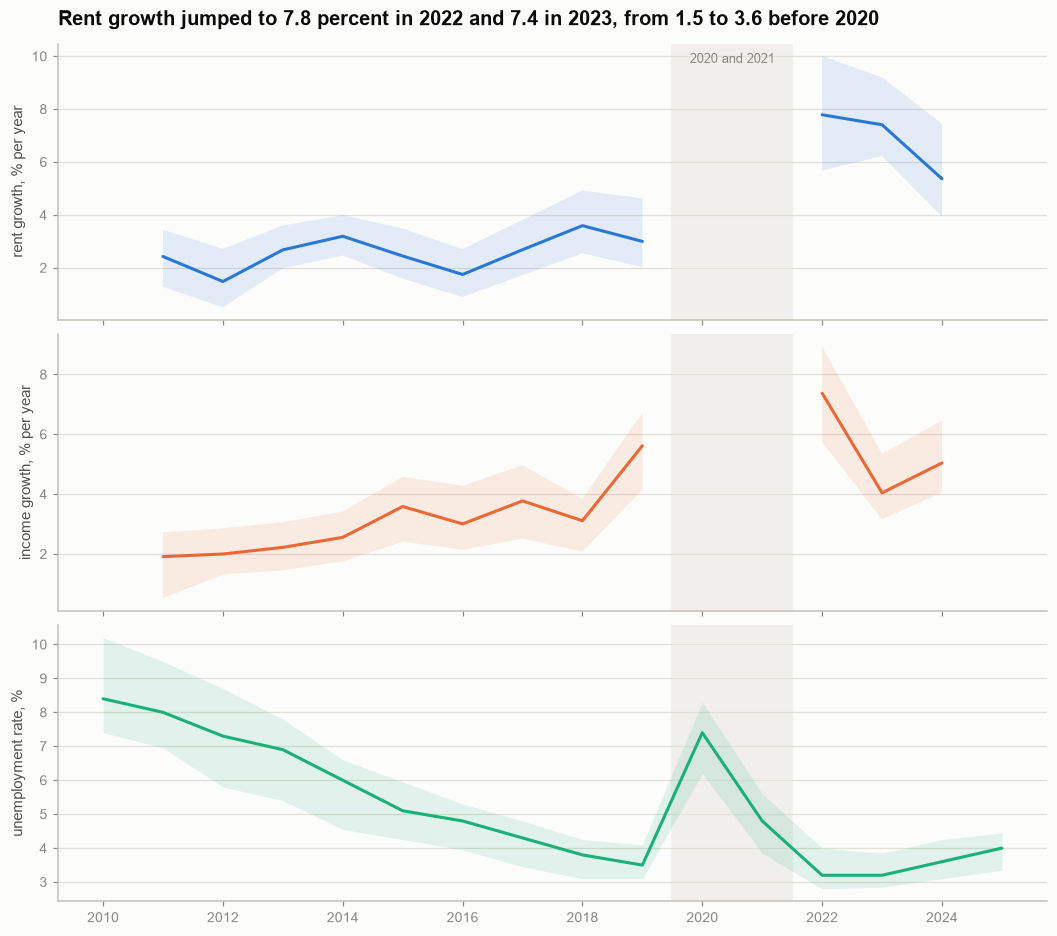

year,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
rent growth,2.4,1.5,2.7,3.2,2.4,1.7,2.7,3.6,3.0,NaN,NaN,7.8,7.4,5.4,NaN
income growth,1.9,2.0,2.2,2.6,3.6,3.0,3.8,3.1,5.6,NaN,NaN,7.4,4.0,5.0,NaN
unemployment rate,8.0,7.3,6.9,6.0,5.1,4.8,4.3,3.8,3.5,7.4,4.8,3.2,3.2,3.6,4.0


In [6]:
rg, ig, un = wide("rent_growth_pct"), wide("income_growth_pct"), wide("unemployment_rate_pct")
rg, ig, un = rg.loc[:, 2010:2025], ig.loc[:, 2010:2025], un.loc[:, 2010:2025]
pre = rg.loc[:, 2011:2019].median()
fig, axes = plt.subplots(3, 1, figsize=(9.5, 8.4), sharex=True)
for ax, w, color, label in zip(axes, (rg, ig, un), SERIES[:3], ("rent growth, % per year", "income growth, % per year", "unemployment rate, %")):
    q1, q3, md = w.quantile(.25), w.quantile(.75), w.median()
    ax.fill_between(w.columns, q1, q3, color=color, alpha=0.12, linewidth=0)
    ax.plot(w.columns, md, color=color)
    ax.set_ylabel(label)
    ax.grid(axis="x", visible=False)
    ax.axvspan(2019.5, 2021.5, color=GRID if False else "#f0efec", zorder=0)
axes[0].set_title(f"Rent growth jumped to {rg[2022].median():.1f} percent in 2022 and {rg[2023].median():.1f} in 2023, from {pre.min():.1f} to {pre.max():.1f} before 2020")
axes[0].text(2020.5, axes[0].get_ylim()[1] * 0.93, "2020 and 2021", ha="center", fontsize=8.5, color=MUTED)
axes[2].set_xticks(range(2010, 2026, 2))
save_figure(fig, "03_growth_and_unemployment")
plt.show()
display(pd.DataFrame({"rent growth": rg.median(), "income growth": ig.median(), "unemployment rate": un.median()}).loc[2011:2025].round(1).T)

## 4. Do states keep their place?

Each state's severe burden averaged over 2010 to 2012 against 2022 to 2024 (three-year averages, which damp the
sampling noise from notebook 1.2). States on the diagonal did not change; below it, the burden fell.

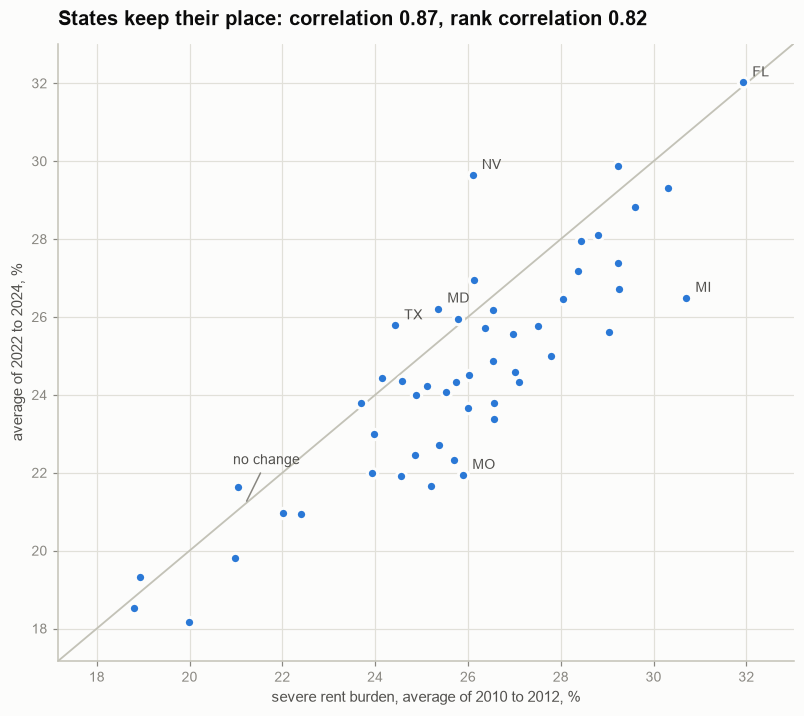

severe burden fell in 40 of 51 states between the two periods; median change -1.41 points


,2010-12,2022-24,change,state
state_abbr,,,,
MI,30.7,26.5,-4.2,Michigan
MO,25.9,21.9,-4.0,Missouri
WI,25.2,21.7,-3.5,Wisconsin
MD,25.4,26.2,0.9,Maryland
TX,24.4,25.8,1.4,Texas
NV,26.1,29.6,3.5,Nevada


In [7]:
a1, a2 = sv[[2010, 2011, 2012]].mean(axis=1), sv[[2022, 2023, 2024]].mean(axis=1)
pear, spear = a1.corr(a2), a1.corr(a2, method="spearman")
n_fell = int((a2 < a1).sum())
fig, ax = plt.subplots(figsize=(7.2, 6.4))
lo, hi_ = min(a1.min(), a2.min()) - 1, max(a1.max(), a2.max()) + 1
ax.plot([lo, hi_], [lo, hi_], color=BASELINE, lw=1.2, zorder=1)
ax.scatter(a1, a2, s=46, color=SERIES[0], edgecolor=SURFACE, linewidth=2, zorder=3)
ax.set_xlim(lo, hi_); ax.set_ylim(lo, hi_)
ax.set_xlabel("severe rent burden, average of 2010 to 2012, %")
ax.set_ylabel("average of 2022 to 2024, %")
ax.set_title(f"States keep their place: correlation {pear:.2f}, rank correlation {spear:.2f}")
d = a2 - a1
for st in list(d.nlargest(3).index) + list(d.nsmallest(2).index) + [a2.idxmax()]:
    ax.annotate(st, (a1[st], a2[st]), xytext=(6, 4), textcoords="offset points", fontsize=9, color=INK_2)
ax.annotate("no change", (21.2, 21.2), xytext=(-8, 26), textcoords="offset points", fontsize=9, color=INK_2, arrowprops=dict(arrowstyle="-", color=MUTED, lw=1))
save_figure(fig, "03_rank_stability")
plt.show()
print(f"severe burden fell in {n_fell} of 51 states between the two periods; median change {d.median():.2f} points")
display(pd.DataFrame({"2010-12": a1, "2022-24": a2, "change": d}).round(1).assign(state=lambda x: x.index.map(names)).sort_values("change").iloc[[0, 1, 2, -3, -2, -1]])

## Findings

1. **Rent and income rose together in the typical state.** From 2010 to 2024 the median state's rent index reached 161.6 and
   its household income index 161.1. The national rent CPI reached 168.4, and per capita personal income, a broader and
   different concept, 179.2.
2. **But rent outgrew income in 38 of 51 states.** The median state gap was 2.9 points (interquartile range -0.3 to +11.1).
   The largest gaps were in the Mountain West and Sunbelt: Colorado (rent +111 percent, income +80), Arizona and
   Utah (about +24 points each), Washington (+22), Nevada and Texas (+20). DC is the main exception, where income grew
   80 percent and rent 61 percent.
3. **Rent's share of income rose in 38 states and fell in 13**, with a median change of only +0.4 points. The rises
   were biggest in Colorado (+3.4), Arizona (+3.0), and Nevada (+2.9); the falls in DC (-2.5), Mississippi (-1.8), and
   Hawaii (-1.4).
4. **The target moved in a U.** The median state's severe burden fell from 26.2 percent in 2010 to 22.1 in 2019, jumped to
   25.1 in 2021, and was 24.4 in 2024: improved over the decade, then lost most of two points and has recovered only a
   little. In 2024 states ranged from 16.8 percent (North Dakota and South Dakota) to 32.1 (Florida). 2020 is missing, so
   the 2019 to 2021 jump cannot be split by year.
5. **Rent growth, not unemployment, marks the break.** Median rent growth ran 1.5 to 3.6 percent a year from 2011 to 2019,
   then 7.8 percent in 2022, 7.4 in 2023, and 5.4 in 2024. Income growth was 7.4, 4.0, and 5.0 in those years, so median rent
   growth exceeded median income growth by 3.4 points in 2023. Unemployment spiked to 7.4 percent in 2020 and was back to 3.2 by 2022, so the
   post-2021 burden is not an unemployment story.
6. **States keep their place, but not their level.** Three-year averages for 2010 to 2012 and 2022 to 2024 correlate 0.87
   (rank correlation 0.82), so the cross-state ranking is persistent enough to support a need index. 40 of 51 states
   improved (median fall 1.4 points), led by Michigan (-4.2), Missouri (-4.0), and Wisconsin (-3.5), while Nevada
   (+3.5), Texas (+1.4), and Maryland (+0.9) worsened.

**What this means for the modeling plan**

* The post-2021 rent shock is a different regime from 2011 to 2019. A rolling-origin test will see few origins that include
  it, and the largest forecast errors will fall in 2022 and 2023, so results must be reported with and without those
  years as well as with and without 2021, and the Bayesian model should be allowed time-varying common effects.
* Common year effects carry much of the movement (notebook 1.2), and rent growth in the Mountain West and Sunbelt diverges
  from the rest, so the fixed-effects model should be tested for regional heterogeneity (region-by-year effects) and the
  Pesaran test for cross-state dependence matters.
* For the need index, current level matters more than the 2010 to 2024 change, but states whose burden is rising (Nevada,
  Texas, Maryland) should be flagged separately from states with a high level that is falling (Michigan, from the
  highest three-year average in 2010 to 2012 after Florida) and from Florida, which stays at the top without moving.

**Caveat.** These are medians of state values, so they describe the typical state and are not population-weighted. A
population-weighted national series would give California, Texas, Florida, and New York more weight.